# Heart Disease Prediction Using Machine Learning

**Course:** Introduction to Machine Learning  
**University:** Umm Al-Qura University  
**Department:** Computer Science  
**Academic Year:** 2025–2026

---

**Dataset Source:** [Heart Failure Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

---

## 1. Introduction

Heart disease is one of the leading causes of death around the world. It happens when the heart cannot work properly, often because the blood vessels are blocked or damaged. Millions of people suffer from it every year, and detecting it early can help save lives.

Machine learning can help doctors predict whether a patient is likely to have heart disease based on medical data like age, blood pressure, cholesterol level, and other factors. Instead of relying only on experience, a machine learning model can analyze many patient records and learn patterns that are hard for humans to notice.

In this project, we will:
- Load and explore a real heart disease dataset from Kaggle
- Visualize the data to understand it better
- Preprocess the data to prepare it for training
- Train two machine learning models: Logistic Regression and Random Forest
- Evaluate and compare the models
- Identify the most important features for prediction

## Setup: Import Libraries

In [1]:
# Import all needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, roc_curve
)

import warnings
warnings.filterwarnings('ignore')

# Set a consistent style for all plots
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

print("All libraries imported successfully!")

# Folder where the plots are saved
import os
IMG_DIR = '../images/'
os.makedirs(IMG_DIR, exist_ok=True)

All libraries imported successfully!


## Load the Dataset

The file `heart.csv` is included in the `data/` folder of this repository (source: [Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)).

- **Running locally:** the next cell reads `../data/heart.csv` directly.
- **Running in Google Colab:** download `heart.csv` from Kaggle (or from this repo), run the next cell, and pick the file when the upload button appears.

In [2]:
# Load the dataset
# Locally: the file is in the data/ folder of this repo.
# In Google Colab: a file picker appears so you can upload heart.csv.
import os

DATA_PATH = '../data/heart.csv'
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()  # select heart.csv
    DATA_PATH = 'heart.csv'

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")

Dataset loaded successfully!
Shape: (918, 12)


## 2. Dataset Understanding

Before we start building models, we need to understand the dataset. This includes looking at the columns, data types, missing values, and basic statistics.

The dataset contains **918 patient records** and **12 features** including the target variable `HeartDisease`.

In [3]:
# Show the first 5 rows of the dataset
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
# Show column names and their data types
print("Columns and Data Types:")
print(df.dtypes)

Columns and Data Types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object


**Feature Descriptions:**

| Feature | Description |
|---|---|
| Age | Age of the patient in years |
| Sex | Sex of the patient (M/F) |
| ChestPainType | Type of chest pain (TA, ATA, NAP, ASY) |
| RestingBP | Resting blood pressure (mm Hg) |
| Cholesterol | Serum cholesterol (mg/dL) |
| FastingBS | Fasting blood sugar (1 = >120 mg/dL, 0 = normal) |
| RestingECG | Resting ECG results (Normal, ST, LVH) |
| MaxHR | Maximum heart rate achieved |
| ExerciseAngina | Exercise-induced angina (Y/N) |
| Oldpeak | ST depression induced by exercise |
| ST_Slope | Slope of the peak exercise ST segment (Up, Flat, Down) |
| HeartDisease | Target: 1 = Heart Disease, 0 = Normal |

In [5]:
# Check for missing values
print("Missing Values per Column:")
print(df.isnull().sum())

Missing Values per Column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [6]:
# Basic descriptive statistics for numerical columns
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [7]:
# Check the target variable distribution
print("Target Variable (HeartDisease) Distribution:")
print(df['HeartDisease'].value_counts())
print("\n0 = No Heart Disease, 1 = Heart Disease")

Target Variable (HeartDisease) Distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64

0 = No Heart Disease, 1 = Heart Disease


## 3. Exploratory Data Analysis (EDA)

In this section, we will create some visualizations to better understand the data. EDA helps us see patterns and relationships between features before training the model.

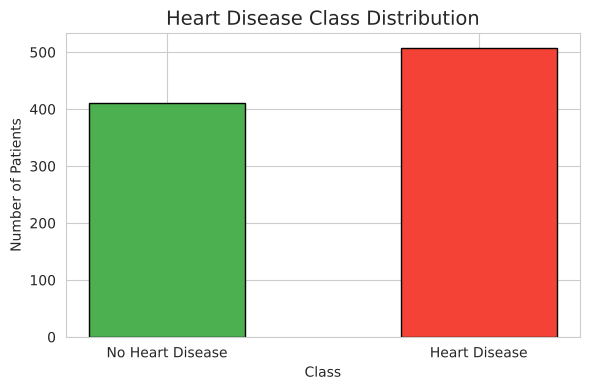

Patients with heart disease: 508 (55.3%)
Patients without heart disease: 410 (44.7%)


In [8]:
# --- Plot 1: Target Class Distribution ---
plt.figure(figsize=(6, 4))
labels = ['No Heart Disease', 'Heart Disease']
counts = df['HeartDisease'].value_counts()
colors = ['#4CAF50', '#F44336']

plt.bar(labels, [counts[0], counts[1]], color=colors, edgecolor='black', width=0.5)
plt.title('Heart Disease Class Distribution', fontsize=14)
plt.xlabel('Class')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.savefig(IMG_DIR + 'target_distribution.png', dpi=100)
plt.show()

print(f"Patients with heart disease: {counts[1]} ({counts[1]/len(df)*100:.1f}%)")
print(f"Patients without heart disease: {counts[0]} ({counts[0]/len(df)*100:.1f}%)")

**Observation:** The dataset is slightly imbalanced — there are more patients with heart disease than without. This is something to keep in mind when evaluating our models. We will use F1-score and ROC-AUC in addition to accuracy to get a fair evaluation.

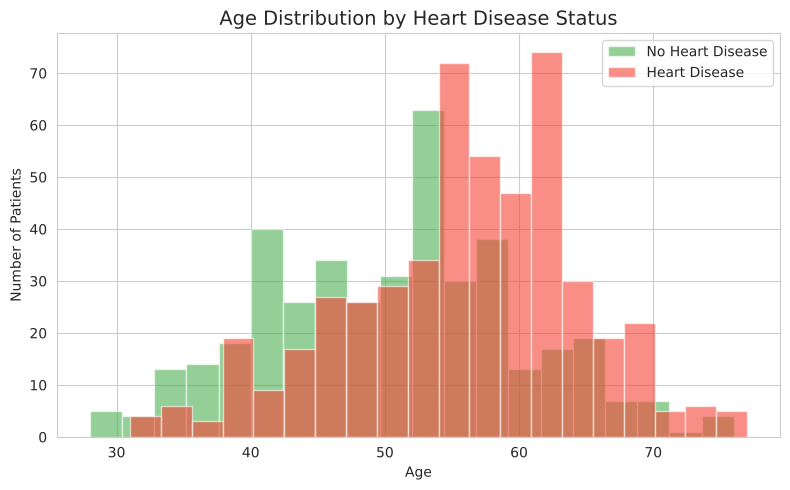

In [9]:
# --- Plot 2: Age Distribution by Heart Disease Status ---
plt.figure(figsize=(8, 5))

df[df['HeartDisease'] == 0]['Age'].plot(kind='hist', bins=20, alpha=0.6,
                                         color='#4CAF50', label='No Heart Disease')
df[df['HeartDisease'] == 1]['Age'].plot(kind='hist', bins=20, alpha=0.6,
                                         color='#F44336', label='Heart Disease')

plt.title('Age Distribution by Heart Disease Status', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.legend()
plt.tight_layout()
plt.savefig(IMG_DIR + 'age_distribution.png', dpi=100)
plt.show()

**Observation:** Most patients with heart disease are older (between 50–65 years). This makes sense because the risk of heart disease increases with age. Younger patients tend to be in the "No Heart Disease" group.

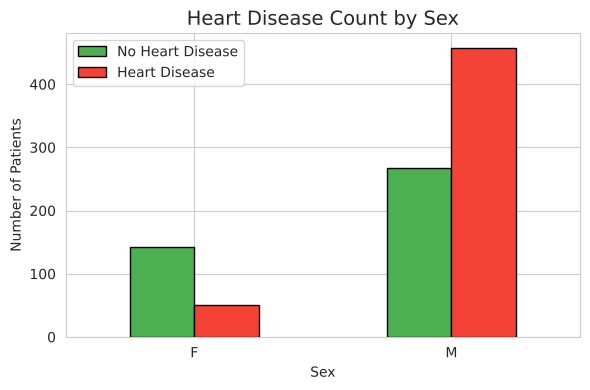

In [10]:
# --- Plot 3: Heart Disease by Sex ---
plt.figure(figsize=(6, 4))
sex_counts = df.groupby(['Sex', 'HeartDisease']).size().unstack()
sex_counts.plot(kind='bar', color=['#4CAF50', '#F44336'], edgecolor='black',
                ax=plt.gca())

plt.title('Heart Disease Count by Sex', fontsize=14)
plt.xlabel('Sex')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(['No Heart Disease', 'Heart Disease'])
plt.tight_layout()
plt.savefig(IMG_DIR + 'sex_distribution.png', dpi=100)
plt.show()

**Observation:** Male patients (M) have a higher count of heart disease cases compared to female patients (F) in this dataset. This could be because there are more male patients in the dataset overall.

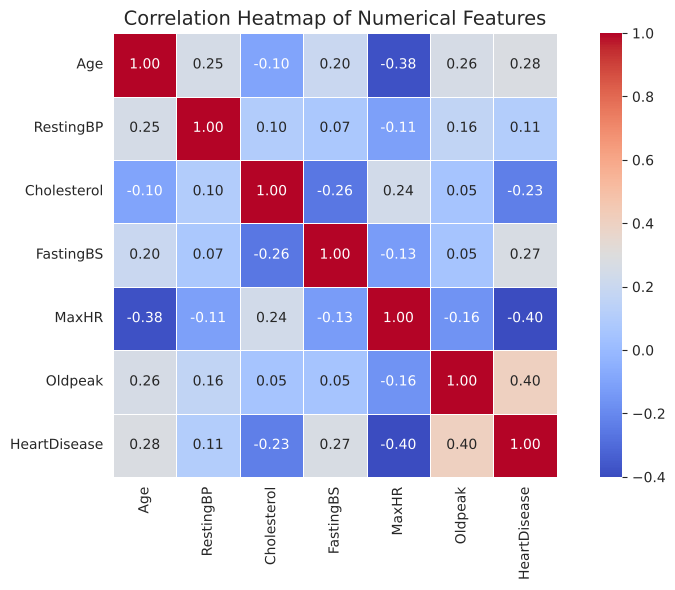

In [11]:
# --- Plot 4: Correlation Heatmap (numerical features only) ---
plt.figure(figsize=(9, 6))

# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, square=True)

plt.title('Correlation Heatmap of Numerical Features', fontsize=14)
plt.tight_layout()
plt.savefig(IMG_DIR + 'correlation_heatmap.png', dpi=100)
plt.show()

**Observation:** From the heatmap, we can see that `Oldpeak`, `FastingBS`, and `Age` have a positive correlation with `HeartDisease`, meaning higher values of these features tend to appear more in patients with heart disease. `MaxHR` has a negative correlation, meaning patients with higher maximum heart rates are less likely to have heart disease.

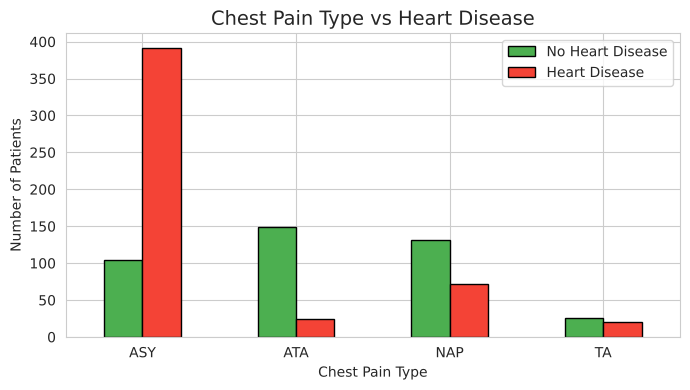

In [12]:
# --- Plot 5: Chest Pain Type vs Heart Disease ---
plt.figure(figsize=(7, 4))
cp_counts = df.groupby(['ChestPainType', 'HeartDisease']).size().unstack()
cp_counts.plot(kind='bar', color=['#4CAF50', '#F44336'], edgecolor='black',
               ax=plt.gca())

plt.title('Chest Pain Type vs Heart Disease', fontsize=14)
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(['No Heart Disease', 'Heart Disease'])
plt.tight_layout()
plt.savefig(IMG_DIR + 'chestpain_distribution.png', dpi=100)
plt.show()

**Observation:** Patients with **ASY (Asymptomatic)** chest pain type have the highest number of heart disease cases. This is interesting because these patients do not show obvious symptoms, which makes machine learning prediction even more valuable.

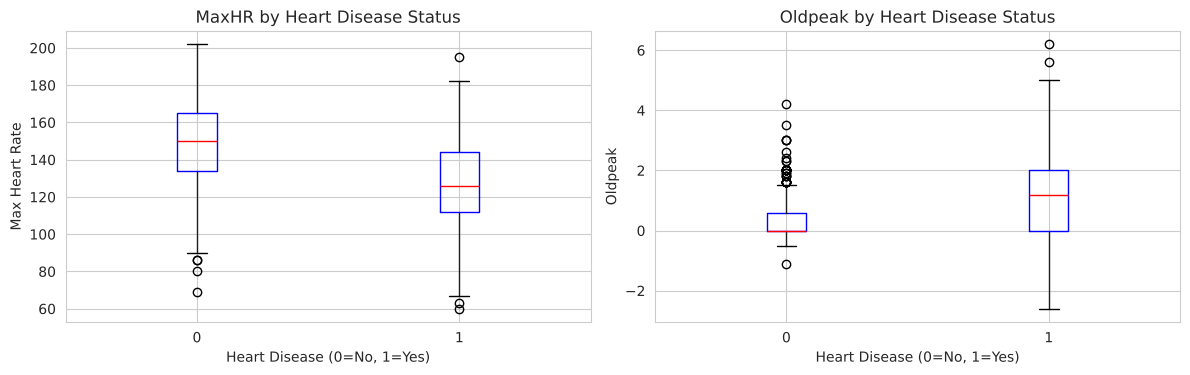

In [13]:
# --- Plot 6: MaxHR and Oldpeak distributions ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# MaxHR boxplot
df.boxplot(column='MaxHR', by='HeartDisease', ax=axes[0],
           boxprops=dict(color='blue'),
           medianprops=dict(color='red'))
axes[0].set_title('MaxHR by Heart Disease Status')
axes[0].set_xlabel('Heart Disease (0=No, 1=Yes)')
axes[0].set_ylabel('Max Heart Rate')

# Oldpeak boxplot
df.boxplot(column='Oldpeak', by='HeartDisease', ax=axes[1],
           boxprops=dict(color='blue'),
           medianprops=dict(color='red'))
axes[1].set_title('Oldpeak by Heart Disease Status')
axes[1].set_xlabel('Heart Disease (0=No, 1=Yes)')
axes[1].set_ylabel('Oldpeak')

plt.suptitle('')
plt.tight_layout()
plt.savefig(IMG_DIR + 'feature_boxplots.png', dpi=100)
plt.show()

**Observation:** Patients with heart disease tend to have **lower MaxHR** and **higher Oldpeak** values. These features look like they will be useful for our prediction model.

## 4. Data Preprocessing

Before training our models, we need to prepare the data. This includes:
- Encoding categorical (text) columns into numbers
- Scaling numerical features
- Splitting the data into training and testing sets

In [14]:
# Step 1: Encode categorical (text) columns into numbers
# We use LabelEncoder to convert text categories to numeric values

# Make a copy so we don't change the original dataframe
df_processed = df.copy()

# List of categorical columns
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

le = LabelEncoder()

for col in categorical_cols:
    df_processed[col] = le.fit_transform(df_processed[col])

df_processed.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [15]:
# Step 2: Separate features (X) and target variable (y)
X = df_processed.drop('HeartDisease', axis=1)  # All columns except target
y = df_processed['HeartDisease']               # Target column

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (918, 11)
Target shape (y): (918,)


In [16]:
# Step 3: Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size:  {X_test.shape[0]} samples")

Training set size: 734 samples
Testing set size:  184 samples


In [17]:
# Step 4: Feature Scaling using StandardScaler
# This makes all numerical features have the same scale (mean=0, std=1)
# It helps models like Logistic Regression work better

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)  # Fit on training data, then transform
X_test_scaled  = scaler.transform(X_test)        # Only transform test data (no fitting!)

print("Scaling complete!")
print("Training features mean (should be ~0):", X_train_scaled.mean().round(4))
print("Training features std  (should be ~1):", X_train_scaled.std().round(4))

Scaling complete!
Training features mean (should be ~0): -0.0
Training features std  (should be ~1): 1.0


## 5. Model Training

We will train two different machine learning models (the Random Forest is trained in the next section, with tuning) and then compare their performance:

1. **Logistic Regression** — A simple and widely used classification algorithm. It works well when the relationship between features and the target is mostly linear. It is easy to understand and fast to train.

2. **Random Forest** — An ensemble method that builds many decision trees and combines their results. It usually gives better accuracy and can handle complex relationships between features.

In [18]:
# --- Model 1: Logistic Regression ---
# Simple and interpretable model — good baseline for classification

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## 6. Hyperparameter Tuning (Random Forest)

We will use **GridSearchCV** to try different combinations of hyperparameters for the Random Forest model and find the best settings. We only apply this to Random Forest because Logistic Regression has fewer parameters to tune.

In [19]:
# Define a simple grid of hyperparameters to try
param_grid = {
    'n_estimators': [50, 100, 150],       # Number of trees
    'max_depth': [None, 5, 10],           # Maximum depth of each tree
    'min_samples_split': [2, 5]           # Minimum samples to split a node
}

# GridSearchCV tries all combinations using 5-fold cross-validation
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)
best_rf_model = grid_search.best_estimator_

print("Best hyperparameters found:")
print(grid_search.best_params_)
print(f"\nBest cross-validation accuracy: {grid_search.best_score_:.4f}")

Best hyperparameters found:
{'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 50}

Best cross-validation accuracy: 0.8596


## 7. Model Evaluation

Now we will evaluate both models on the test set using several metrics:

- **Accuracy:** What percentage of predictions are correct
- **F1-score:** Balances precision and recall — useful when classes are slightly imbalanced
- **ROC-AUC:** Measures how well the model separates the two classes
- **Confusion Matrix:** Shows how many predictions were correct and where the model made mistakes
- **ROC Curve:** Visualizes the trade-off between true positive rate and false positive rate

In [20]:
# Helper function to evaluate any model
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc    = accuracy_score(y_test, y_pred)
    f1     = f1_score(y_test, y_pred)
    roc    = roc_auc_score(y_test, y_prob)

    print(f"=== {model_name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['No Heart Disease', 'Heart Disease']))
    return acc, f1, roc, y_pred, y_prob

In [21]:
# Evaluate Logistic Regression
lr_acc, lr_f1, lr_roc, lr_pred, lr_prob = evaluate_model(
    lr_model, X_test_scaled, y_test, "Logistic Regression"
)

=== Logistic Regression ===
Accuracy : 0.8696
F1-Score : 0.8879
ROC-AUC  : 0.8971

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.90      0.79      0.84        82
   Heart Disease       0.85      0.93      0.89       102

        accuracy                           0.87       184
       macro avg       0.88      0.86      0.87       184
    weighted avg       0.87      0.87      0.87       184



In [22]:
# Evaluate Best Random Forest
rf_acc, rf_f1, rf_roc, rf_pred, rf_prob = evaluate_model(
    best_rf_model, X_test_scaled, y_test, "Random Forest (Tuned)"
)

=== Random Forest (Tuned) ===
Accuracy : 0.8750
F1-Score : 0.8930
ROC-AUC  : 0.9280

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.92      0.79      0.85        82
   Heart Disease       0.85      0.94      0.89       102

        accuracy                           0.88       184
       macro avg       0.88      0.87      0.87       184
    weighted avg       0.88      0.88      0.87       184



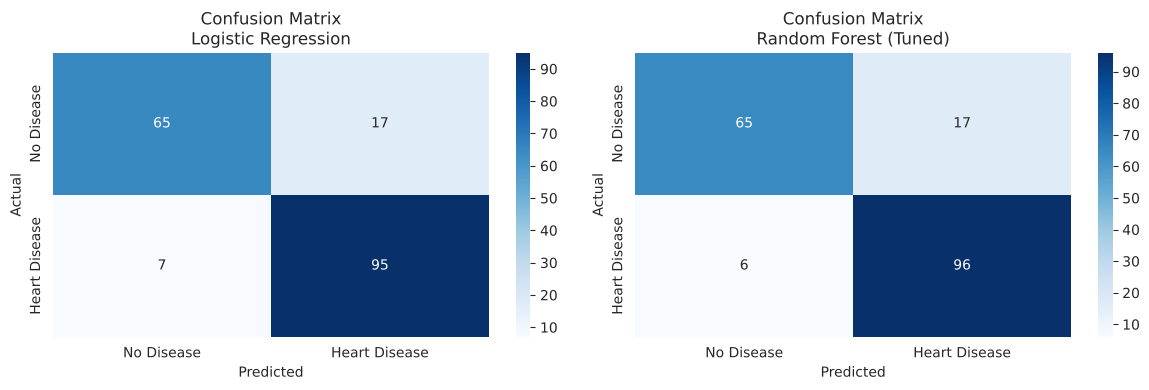

In [23]:
# --- Confusion Matrices ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(
    axes,
    [lr_pred, rf_pred],
    ['Logistic Regression', 'Random Forest (Tuned)']
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Disease', 'Heart Disease'],
                yticklabels=['No Disease', 'Heart Disease'])
    ax.set_title(f'Confusion Matrix\n{title}', fontsize=12)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig(IMG_DIR + 'confusion_matrices.png', dpi=100)
plt.show()

**Reading the Confusion Matrix:**
- **Top-left:** True Negatives — Correctly predicted "No Disease"
- **Top-right:** False Positives — Predicted "Heart Disease" but actually "No Disease"
- **Bottom-left:** False Negatives — Predicted "No Disease" but actually has Heart Disease (most dangerous error!)
- **Bottom-right:** True Positives — Correctly predicted "Heart Disease"

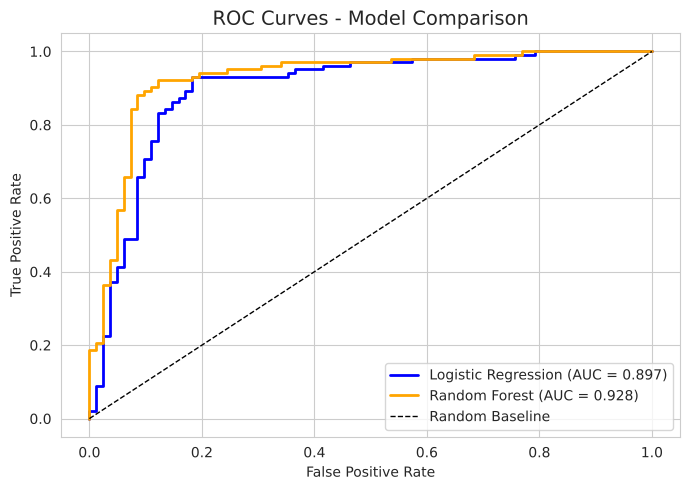

In [24]:
# --- ROC Curves ---
plt.figure(figsize=(7, 5))

# Logistic Regression ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_roc:.3f})',
         color='blue', linewidth=2)

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_roc:.3f})',
         color='orange', linewidth=2)

# Random baseline
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Baseline')

plt.title('ROC Curves - Model Comparison', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(IMG_DIR + 'roc_curves.png', dpi=100)
plt.show()

**Observation:** A better ROC curve is closer to the top-left corner. The higher the AUC value, the better the model is at distinguishing between patients with and without heart disease.

## 8. Model Comparison

Let's create a simple table and bar chart to compare the two models side by side.

In [25]:
# Create a comparison table
comparison_data = {
    'Model': ['Logistic Regression', 'Random Forest (Tuned)'],
    'Accuracy': [round(lr_acc, 4), round(rf_acc, 4)],
    'F1-Score': [round(lr_f1, 4), round(rf_f1, 4)],
    'ROC-AUC':  [round(lr_roc, 4), round(rf_roc, 4)]
}

comparison_df = pd.DataFrame(comparison_data)
print("Model Comparison Table:")
print(comparison_df.to_string(index=False))

Model Comparison Table:
                Model  Accuracy  F1-Score  ROC-AUC
  Logistic Regression    0.8696    0.8879   0.8971
Random Forest (Tuned)    0.8750    0.8930   0.9280


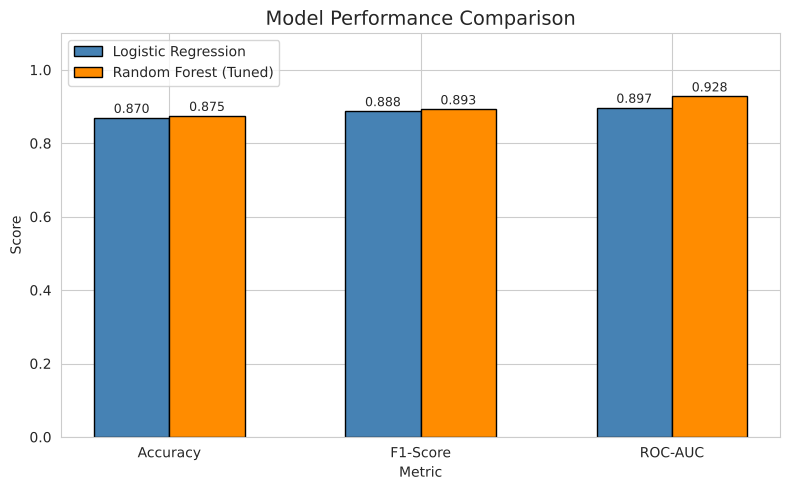

In [26]:
# Bar chart comparing model performance
metrics = ['Accuracy', 'F1-Score', 'ROC-AUC']
lr_scores = [lr_acc, lr_f1, lr_roc]
rf_scores = [rf_acc, rf_f1, rf_roc]

x = np.arange(len(metrics))
width = 0.3

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, lr_scores, width, label='Logistic Regression',
               color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, rf_scores, width, label='Random Forest (Tuned)',
               color='darkorange', edgecolor='black')

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Metric')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend()
plt.tight_layout()
plt.savefig(IMG_DIR + 'model_comparison.png', dpi=100)
plt.show()

**Observation:** The tuned Random Forest is slightly better on all three metrics. The accuracy gap is small: 161 vs 160 correct predictions out of 184 test patients. The clearer difference is in ROC-AUC (0.928 vs 0.897).

## 9. Feature Importance

Random Forest can tell us which features (columns) were most useful for making predictions. This is called **feature importance**. Understanding which features matter the most can help doctors focus on the most important medical indicators.

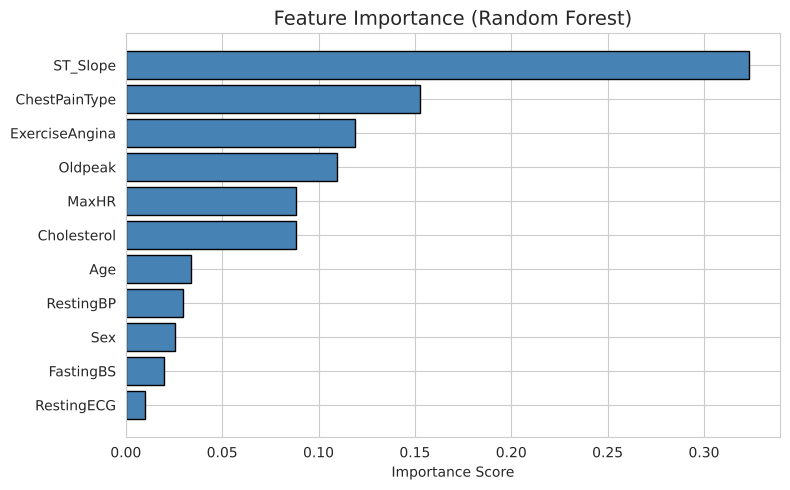


Top 5 Most Important Features:
       Feature  Importance
      ST_Slope    0.323283
 ChestPainType    0.152490
ExerciseAngina    0.118930
       Oldpeak    0.109791
         MaxHR    0.088259


In [27]:
# Get feature importances from the best Random Forest model
feature_names = X.columns.tolist()
importances = best_rf_model.feature_importances_

# Create a sorted DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(8, 5))
plt.barh(importance_df['Feature'], importance_df['Importance'],
         color='steelblue', edgecolor='black')
plt.xlabel('Importance Score')
plt.title('Feature Importance (Random Forest)', fontsize=14)
plt.gca().invert_yaxis()  # Most important feature at the top
plt.tight_layout()
plt.savefig(IMG_DIR + 'feature_importance.png', dpi=100)
plt.show()

print("\nTop 5 Most Important Features:")
print(importance_df.head(5).to_string(index=False))

**Observation:** The top 5 features in the tuned Random Forest are `ST_Slope` (about 0.32), `ChestPainType` (about 0.15), `ExerciseAngina` (about 0.12), `Oldpeak` (about 0.11) and `MaxHR` (about 0.09). All of them come from chest pain type or exercise test results, which are also indicators doctors use when diagnosing heart disease.

Note: feature importance shows what the model relies on. It does not prove that a feature causes heart disease.

## 10. Conclusion

In this project, we built a machine learning system to predict heart disease using patient medical data from Kaggle.

**Main Findings:**
- The **tuned Random Forest** scored slightly higher than Logistic Regression on all three metrics: accuracy 0.875 vs 0.870, F1 0.893 vs 0.888, ROC-AUC 0.928 vs 0.897 (test set of 184 patients).
- The most important features were ST_Slope, ChestPainType, ExerciseAngina, Oldpeak and MaxHR.
- Even Logistic Regression achieved decent accuracy, which shows that some relationships in the data are fairly linear.

**Best Model:**
- Based on accuracy, F1-score, and ROC-AUC, we recommend the **tuned Random Forest** model for this task.

**Limitations:**
- The dataset has 918 samples, which is not very large. A larger dataset might improve the model.
- Some patients had a Cholesterol value of 0, which might be incorrect data. We kept those records but this could affect results.
- We used basic hyperparameter tuning. More advanced techniques could improve the model further.
- The results come from one 80/20 split. The gap between the two models is small, so a different split could change the ranking.
- Categorical columns were label-encoded (turned into 0, 1, 2...). This gives Logistic Regression a fake order between categories; one-hot encoding would be a better choice.

**Future Improvements:**
- Try more machine learning models such as SVM or Gradient Boosting.
- Use a larger and more diverse dataset.
- Apply better feature engineering techniques.
- Deploy the model as a simple web application so doctors can use it.

---

**Dataset:** [Heart Failure Prediction Dataset on Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

**Libraries used:** pandas, numpy, matplotlib, seaborn, scikit-learn